![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team:** Jovana Krstevska
**Dataset:** Telco Customer Churn (IBM sample), Apache 2.0 licence

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV,RandomizedSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, fbeta_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from scipy.stats import loguniform, randint

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

In [3]:
df = load_data()

X_train, X_test, y_train, y_test = split_data(df)

print(f"Train features shape: {X_train.shape}\nTest features shape: {X_test.shape}\n")
print(f"Train target mean: {y_train.mean().round(3)}\nTest target mean: {y_test.mean().round(3)}") 


Train features shape: (5634, 19)
Test features shape: (1409, 19)

Train target mean: 0.265
Test target mean: 0.265


---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

In [4]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]

preprocessor = build_preprocessor(num_cols, cat_cols)
print(preprocessor.fit_transform(X_train).shape)

(5634, 40)


---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [5]:
# Baseline Models
baselines = {
    'Always "No"': DummyClassifier(strategy="most_frequent"),
    'Always "Yes"': DummyClassifier(strategy="constant", constant=1),
}

rows = []
for name, model in baselines.items():
    res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING)
    row = {"baseline": name}
    for metric in SCORING:
        row[metric] = res[f"test_{metric}"].mean()
    rows.append(row)

baseline_table = pd.DataFrame(rows).set_index("baseline").round(3)
baseline_table

,f2,average_precision,recall,precision,f1,accuracy
baseline,,,,,,
"Always ""No""",0.000,0.265,0.0,0.000,0.000,0.735
"Always ""Yes""",0.644,0.265,1.0,0.265,0.419,0.265


In [6]:
# First model: logistic regression, scored with the same CV as the baselines

pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

res = cross_validate(pipe_lr, X_train, y_train, cv=CV, scoring=SCORING)

lr_mean = {metric: res[f"test_{metric}"].mean() for metric in SCORING}
lr_std = {metric: res[f"test_{metric}"].std() for metric in SCORING}

first_model_table = pd.concat([
    baseline_table,
    pd.DataFrame([lr_mean], index=["LogisticRegression"]),
    pd.DataFrame([lr_std], index=["LogisticRegression (std)"]),
]).round(3)

first_model_table

,f2,average_precision,recall,precision,f1,accuracy
"Always ""No""",0.000,0.265,0.000,0.000,0.000,0.735
"Always ""Yes""",0.644,0.265,1.000,0.265,0.419,0.265
LogisticRegression,0.720,0.652,0.801,0.513,0.625,0.745
LogisticRegression (std),0.005,0.030,0.005,0.011,0.008,0.008


Logistic regression reaches recall 0.801 and F2 0.720 against 0.64 for the 'Always "yes"'baseline , by far more than the fold of spreads. 'Always “no”' has higher accuracy (0.735) but catches no churners, which is why accuracy isn’t used. Average precision rises from 0.265 to 0.652, so the model ranks churners well independent of the threshold.

---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

In [7]:
# Feature engineering: each new feature tested on its own, same model and same folds

feature_sets = {
    "No new features": (),
    "n_addons": ("n_addons",),
    "new_customer": ("new_customer",),
    "con_serv": ("con_serv",),
}

tables = [baseline_table]
for name, feats in feature_sets.items():
    pipe = Pipeline([
        ("features", FunctionTransformer(add_features, kw_args={"features": feats})),
        ("prep", build_preprocessor(num_cols + list(feats), cat_cols)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING)

    feat_mean = {metric: res[f"test_{metric}"].mean() for metric in SCORING}
    feat_std = {metric: res[f"test_{metric}"].std() for metric in SCORING}

    tables.append(pd.DataFrame([feat_mean], index=[name]))
    tables.append(pd.DataFrame([feat_std], index=[f"{name} (std)"]))

feature_table = pd.concat(tables).round(3)
feature_table

,f2,average_precision,recall,precision,f1,accuracy
"Always ""No""",0.000,0.265,0.000,0.000,0.000,0.735
"Always ""Yes""",0.644,0.265,1.000,0.265,0.419,0.265
No new features,0.720,0.652,0.801,0.513,0.625,0.745
No new features (std),0.005,0.030,0.005,0.011,0.008,0.008
n_addons,0.721,0.652,0.802,0.513,0.625,0.745
n_addons (std),0.005,0.030,0.005,0.010,0.007,0.008
new_customer,0.718,0.653,0.799,0.512,0.624,0.745
new_customer (std),0.006,0.031,0.010,0.010,0.007,0.008
con_serv,0.720,0.652,0.801,0.514,0.626,0.746
con_serv (std),0.005,0.030,0.006,0.012,0.008,0.009


## Features tested: logistic regression, same 5 folds

- No features - recall: 0.801; F2 score: 0.720
- n_addons - recall: 0.802; F2 score: 0.721
- new_customer - recall: 0.799; F2 score: 0.718
- con_serv - recall: 0.801; F2 score: 0.720

n_addons (number of internet add-ons): recall increased by 0.001, same with F2. This is inside the noise, because the feature is just the sum of add-on columns the model already sees.
new_customer (tenure <= 12 months): recall decreased by 0.002 and F2 decreased by 0.002, also inside the noise. The early-tenure effect is probably already captured by Contract (month-to-month) and tenure, so the flag added nothing measurable.
con_serv (month-to-month contract anf fiber optics): no change in the recall or the F2. The combination isn’t riskier than the two effects added together, which the model already does.

None of the features improve the cross-validated score beyond the spread across folds, so the models from section 5 onward use the original columns only.

---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

In [8]:
candidates = {
    'Always "No"': DummyClassifier(strategy="most_frequent"),
    'Always "Yes"': DummyClassifier(strategy="constant", constant=1),
    'LogisticRegression': make_pipeline(preprocessor, LogisticRegression(max_iter=1000, class_weight='balanced')),
    "KNN": make_pipeline(preprocessor, KNeighborsClassifier()),
    "SVM (RBF kernel)": make_pipeline(preprocessor, SVC(class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision tree": make_pipeline(preprocessor, DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    "Random forest": make_pipeline(preprocessor, RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    "HistGradientBoosting": make_pipeline(preprocessor, HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
}
model_comparison_table = compare_models(candidates, X_train, y_train, CV, SCORING)
model_comparison_table

,F2,F2 std,recall,precision,accuracy
model,,,,,
LogisticRegression,0.720,0.005,0.801,0.513,0.745
SVM (RBF kernel),0.709,0.007,0.780,0.520,0.750
HistGradientBoosting,0.686,0.016,0.736,0.540,0.764
"Always ""Yes""",0.644,0.000,1.000,0.265,0.265
Random forest,0.629,0.016,0.649,0.560,0.771
KNN,0.536,0.028,0.527,0.575,0.771
Decision tree,0.491,0.018,0.492,0.489,0.729
"Always ""No""",0.000,0.000,0.000,0.000,0.735


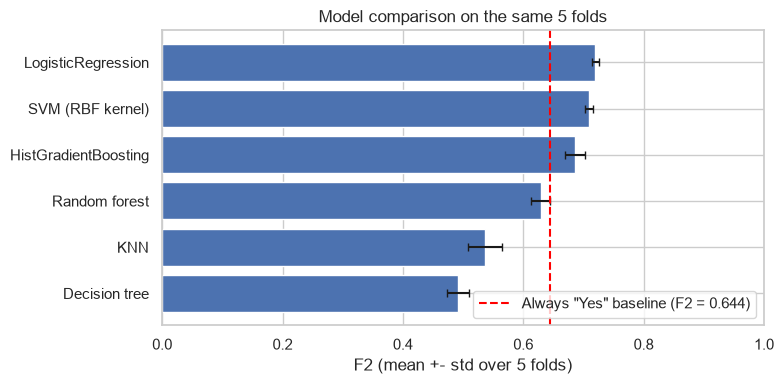

In [9]:
baseline_f2 = model_comparison_table.loc['Always "Yes"', "F2"]

# Plot the real models only and the baseline is drawn as a line
to_plot = (model_comparison_table.drop(index=['Always "No"', 'Always "Yes"']).sort_values("F2"))  

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(to_plot.index, to_plot["F2"], xerr=to_plot["F2 std"], capsize=3)
ax.axvline(baseline_f2, color="red", linestyle="--",
           label=f'Always "Yes" baseline (F2 = {baseline_f2:.3f})')
ax.set_xlabel("F2 (mean +- std over 5 folds)")
ax.set_title("Model comparison on the same 5 folds")
ax.set_xlim(0, 1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

All models beat the baseline. Logistic regression, SVM and HistGradientBoosting are tied on F1 (0.625, 0.624, 0.623, all within each other’s spread). Logistic regression has the best recall (0.801). 

Model to tune: logistic regression (best recall, simplest) and HistGradientBoosting (best tree model). SVM is not tuned because it is slow and offers no advantage.
All models are compared at the default threshold (0.5) on the same 5 folds. Logistic regression, SVM and HistGradientBoosting are the top three, with F2 within each other’s spread. All of them clear the always-“Yes” baseline (F2 0.644) by more than the fold spread. KNN and the decision tree barely beat it or fall below it, so they are dropped. 

We tune logistic regression (simplest, highest recall) and HistGradientBoosting (best tree-based model). SVM is not tuned, it is slow and offers no advantage over logistic regression.

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [10]:
pipe = Pipeline([("prep", preprocessor),
                 ("model", LogisticRegression())])

param_grid = [
    {"model": [LogisticRegression(max_iter=5000, class_weight="balanced")],
     "model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"model": [HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)],
     "model__learning_rate": [0.03, 0.1, 0.3],
     "model__max_depth": [3, 5, None],
     "model__min_samples_leaf": [20, 50]},
]
search = GridSearchCV(pipe, param_grid, cv=CV, scoring=SCORING, refit="f2", n_jobs=-1)
search.fit(X_train, y_train)

def model_name(m):
    return type(m).__name__

def settings(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items() if k != "model")

results = pd.DataFrame(search.cv_results_)
results["model"] = results["param_model"].map(model_name)
results["settings"] = results["params"].map(settings)
results[["model", "settings", "mean_test_f2", "std_test_f2", "mean_test_recall", "rank_test_f2"]] \
    .sort_values("rank_test_f2").head(10).round(3)

,model,settings,mean_test_f2,std_test_f2,mean_test_recall,rank_test_f2
7,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=3, min_samples_l...",0.725,0.007,0.807,1
6,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=3, min_samples_l...",0.725,0.006,0.807,2
12,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=3, min_samples_le...",0.724,0.010,0.801,3
2,LogisticRegression,C=0.1,0.723,0.005,0.803,4
13,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=3, min_samples_le...",0.722,0.008,0.799,5
3,LogisticRegression,C=1,0.720,0.005,0.801,6
9,HistGradientBoostingClassifier,"learning_rate=0.03, max_depth=5, min_samples_l...",0.720,0.010,0.793,7
4,LogisticRegression,C=10,0.720,0.007,0.802,8
5,LogisticRegression,C=100,0.719,0.006,0.801,9
15,HistGradientBoostingClassifier,"learning_rate=0.1, max_depth=5, min_samples_le...",0.718,0.013,0.784,10


In [11]:
lr_results = results[results["model"] == "LogisticRegression"].sort_values("rank_test_f2")
display(lr_results[["settings", "mean_test_f2", "std_test_f2", "mean_test_recall"]].head(1).round(3))

best_C = lr_results.iloc[0]["param_model__C"]
best_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(C=best_C, max_iter=5000, class_weight="balanced")),
])
best_model.fit(X_train, y_train)
print("Best C:", best_C)

,settings,mean_test_f2,std_test_f2,mean_test_recall
2,C=0.1,0.723,0.005,0.803


Best C: 0.1


In [12]:
print("Best settings:", search.best_params_)
print(f"Best cross-validated F2: {search.best_score_:.3f}")
best_hbg_model = search.best_estimator_    

Best settings: {'model': HistGradientBoostingClassifier(class_weight='balanced', random_state=0), 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 50}
Best cross-validated F2: 0.725


Tuning was done with `GridSearchCV` on the training set, refitting on F2. The best setting is HistGradientBoosting with `learning_rate=0.03`, `max_depth=3`, `min_samples_leaf=50`, at F2 0.725 +- 0.007. Tuning lifts it from 0.686.

The ranking is flat: the top five configurations are within 0.003 F2 of each other, well inside the fold spread. The best logistic regression (C=0.1) scores 0.723 +- 0.005, only 0.002 lower, so the two families are tied at the default threshold.

The best tree models are all shallow (max_depth=3) and deeper trees score lower. Churn in this data is driven by a few features that act mostly on their own (tenure, contract), with little interaction for trees to exploit. This is why a linear model performs as well.

---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.

In [13]:
# Cross-validated probabilities on the training set: every row is predicted by a model that did not see it

proba_cv = cross_val_predict(best_model, X_train, y_train, cv=CV, method='predict_proba')[:, 1]

rows =[]
for threshold in np.arange(0.20, 0.80, 0.05): 
    pred = (proba_cv >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "f2": fbeta_score(y_train, pred, beta=2),
        "recall": recall_score(y_train, pred),
        "precision": precision_score(y_train, pred),
        "f1": f1_score(y_train, pred),
        "flagged_%": pred.mean() * 100,
        "missed churners": int(((pred == 0) & (y_train == 1)).sum()),
        "false alarms": int(((pred == 1) & (y_train == 0)).sum()),
        })
threshold_table = pd.DataFrame(rows)
threshold_table.round(3)


,threshold,f2,recall,precision,f1,flagged_%,missed churners,false alarms
0,0.20,0.732,0.955,0.379,0.543,66.897,67,2341
1,0.25,0.740,0.941,0.399,0.560,62.620,88,2121
2,0.30,0.747,0.926,0.421,0.579,58.360,110,1903
3,0.35,0.745,0.901,0.440,0.591,54.331,148,1714
4,0.40,0.738,0.865,0.466,0.606,49.255,202,1482
5,0.45,0.728,0.829,0.489,0.615,45.048,255,1298
6,0.50,0.723,0.803,0.516,0.628,41.321,294,1127
7,0.55,0.701,0.757,0.539,0.630,37.256,363,967
8,0.60,0.672,0.706,0.562,0.626,33.369,439,824
9,0.65,0.641,0.654,0.595,0.623,29.162,517,665


In [14]:
best = TunedThresholdClassifierCV(
    best_model,
    scoring=make_scorer(fbeta_score, beta=2),
    cv=CV,
    store_cv_results=True,
)
best.fit(X_train, y_train)

print(f"Best threshold: {best.best_threshold_:.3f}")
print(f"Best F2: {best.best_score_:.3f}")

Best threshold: 0.319
Best F2: 0.751


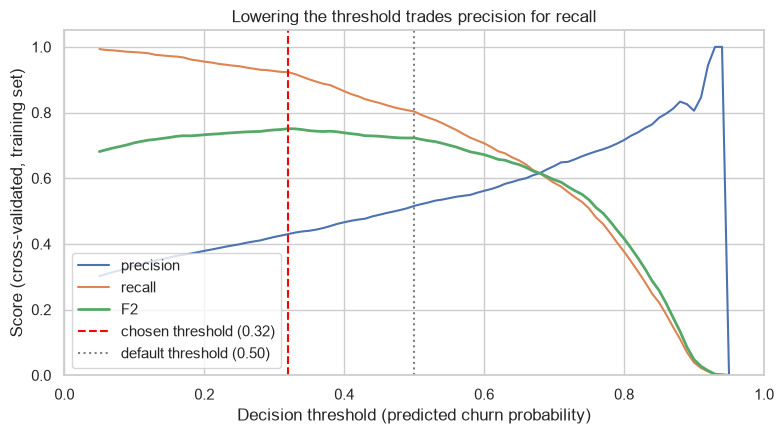

In [15]:
# Precision, recall and F2 against the threshold, from the same cross-validated probabilities
grid = np.arange(0.05, 0.96, 0.01)
curve = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, (proba_cv >= t).astype(int), zero_division=0) for t in grid],
    "recall": [recall_score(y_train, (proba_cv >= t).astype(int)) for t in grid],
    "F2": [fbeta_score(y_train, (proba_cv >= t).astype(int), beta=2) for t in grid],
})

chosen = best.best_threshold_

fig, ax = plt.subplots(figsize=(8, 4.5))
for metric in ["precision", "recall", "F2"]:
    ax.plot(curve["threshold"], curve[metric], label=metric, linewidth=2 if metric == "F2" else 1.5)
ax.axvline(chosen, color="red", linestyle="--", label=f"chosen threshold ({chosen:.2f})")
ax.axvline(0.5, color="grey", linestyle=":", label="default threshold (0.50)")
ax.set_xlabel("Decision threshold (predicted churn probability)")
ax.set_ylabel("Score (cross-validated, training set)")
ax.set_title("Lowering the threshold trades precision for recall")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [16]:
f2 = make_scorer(fbeta_score, beta=2)

final_candidates = {
    "LogisticRegression (C=0.1)": best_model,
    "HistGradientBoosting (tuned)": best_hbg_model,
}

rows = []
for name, model in final_candidates.items():
    tuned = TunedThresholdClassifierCV(model, scoring=f2, cv=CV)
    res = cross_validate(
        tuned, X_train, y_train, cv=CV,
        scoring={
            "f2": f2,
            "recall": "recall",
            "precision": make_scorer(precision_score, zero_division=0),
        },
        return_estimator=True,
        n_jobs=-1,
    )
    thresholds = [est.best_threshold_ for est in res["estimator"]]
    rows.append({
        "model": name,
        "F2": res["test_f2"].mean(),
        "F2 std": res["test_f2"].std(),
        "recall": res["test_recall"].mean(),
        "precision": res["test_precision"].mean(),
        "threshold (mean)": np.mean(thresholds),
    })

tuned_comparison = pd.DataFrame(rows).set_index("model").round(3)
tuned_comparison

,F2,F2 std,recall,precision,threshold (mean)
model,,,,,
LogisticRegression (C=0.1),0.749,0.005,0.917,0.433,0.325
HistGradientBoosting (tuned),0.742,0.009,0.915,0.424,0.336


### Final comparison at tuned thresholds

Both finalists were wrapped in `TunedThresholdClassifierCV` (F2) and evaluated with nested cross-validation: the outer 5 folds score the model, and the threshold is chosen inside each fold on training data only. Both were tuned with `refit="f2"`.

| Model | F2 | F2 std | Recall | Precision | Threshold |
|---|---|---|---|---|---|
| Logistic regression (C=0.1) | 0.749 | 0.005 | 0.917 | 0.433 | 0.325 |
| HistGradientBoosting (tuned) | 0.742 | 0.009 | 0.915 | 0.424 | 0.336 |

- At their own tuned thresholds the two models perform almost identically: the F2 gap (0.007) is smaller than the spread across folds, so neither is better than the other.
- They catch the same share of churners (recall ≈ 0.92) at similar precision (≈ 0.43 vs 0.42) and with nearly the same threshold (≈ 0.33).
- Logistic regression is slightly more stable across folds (F2 std 0.005 vs 0.009).
- Both clearly beat the always-"Yes" baseline (F2 ≈ 0.64).

**Final model: logistic regression** (`C=0.1`, `class_weight="balanced"`) with a threshold of about **0.32**, chosen by F2. Since the two models are tied, the simpler one is preferred: it is more stable, faster to train, and its coefficients show which customer traits raise churn risk, which the retention team can act on. At this threshold it catches about 92% of churners at a precision of about 43%, meaning that roughly 2 in 5 contacted customers would actually have churned.

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

In [17]:
import joblib
MODELS.mkdir(exist_ok=True)
joblib.dump({"model": best, "threshold": best.best_threshold_}, MODELS / "final_model.joblib")

['/Users/jkrstevska/Desktop/DSML/Week 6/project-2-ml/models/final_model.joblib']

## Final model: Logistic Regression
`C=0.1`, `class_weight="balanced"` wrapped in `TunedThresholdClassifierCV` with a threshold of **0.32**, chosen by F2.

After tuning, HistGradientBoosting had the best cross-validated F2 0.749, against 0.742 for logistic regression. The gap is smaller tha the spread across. less than one standard deviation, so the two models are within the noise of each other. The same was true at the default threshold (0.723 vs 0.725). Logistic regression is the final model because it is much simpler and easy to explain, its coefficients show which customer traits raise churn risk, which a retention team can act on.

Threshold: missing a churner costs more than an unnecessary offer, so the threshold favours recall. At 0.32 the model catches about 92% of churners, at the cost of more false alarms.

---
## Image option

If you chose the flower photos, sections 2 to 7 become: rescaling and augmentation layers; a CNN from scratch trained with early stopping, with its training curves; a frozen pretrained network (for example `MobileNetV2`) with a new output layer, trained the same way; and the two compared on the validation set. Fine-tuning the top of the pretrained network is optional.